# Rede Neural MLP com validação cruzada T-Fold e GridSearch

- **Repositório:** `deep-learning-neural-networks`  
- **Tecnologias:** Scikit-Learn  
- **Arquivo Original:** `T_Fold_CrossValidation_GridSearch_MLP.ipynb`  

---


Neste exemplo treinamos e avaliamos um modelo preditivo usando **T-fold-CrossValidation**, ou Validação Cruzada com T Pastas

- técnica de aprendizagem usada: MLP (MultiLayer Perceptron)
- tarefa supervisionada: classificação de vinhos
- métricas de avaliação: taxa de acerto, precisão, revocação, f1 e matriz de confusão

Importando os recursos necessários:
- numpy: biblioteca numérica
- sklearn: biblioteca de machine learning, as métricas de avaliação e o model_selection que nos permite executar validação cruzada

In [13]:
# Importa bibliotecas necessárias
import numpy as np
from sklearn.neural_network import MLPClassifier
from sklearn import model_selection
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.svm import SVC
from sklearn.ensemble import BaggingClassifier
from sklearn.datasets import make_classification
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import AdaBoostClassifier

Carregando a base de dados do problema, representada aqui por X e y, onde:
- X: array contendo N instâncias com M atributos (atributos de entrada do problema)
- y: array contendo o rótulo (atributo alvo) de cada instância em X


In [2]:
# Neste exemplo a base de dados wine é composta por 178 instâncias (N=178)
# e cada instância é representada por um vetor de 13 atributos (M=13)

X, y = load_breast_cancer(return_X_y=True)
print("Formato de X: ", X.shape)
print("Formato de y: ", y.shape)


Formato de X:  (569, 30)
Formato de y:  (569,)


In [12]:
# Usando o GridSearch para buscar os melhores parâmetros para nosso modelo
from sklearn.model_selection import train_test_split, GridSearchCV

# Separando da base original uma base de validação
X, X_val, y, y_val = train_test_split(X,y, test_size=0.2, random_state=42, stratify=y)

# Definindo a técnica a ser utilizada
clf = BaggingClassifier()

# parâmetros que o Gridsearch utilizará em sua busca
parameters = [{'estimator':[DecisionTreeClassifier(),KNeighborsClassifier(),RandomForestClassifier(),GaussianNB()],
               'n_estimators': [5,10,15,20,30],
               'random_state': [10, 46],
               'max_samples':[0.5],
               'max_features': [0.5, 1.0],
               'bootstrap': [False,True],
               'bootstrap_features': [True,False],
               'oob_score':[True,False],
               'warm_start': [True,False],
               'n_jobs':[1,-1],
               }]

# Execução do Gridsearch
gs=GridSearchCV(clf, parameters, scoring='accuracy', cv=3, n_jobs=-1)
gs.fit(X_val, y_val)

# Mostrando a tabela de resultados do GridSearch (opcional)
from tabulate import tabulate
import pandas as pd
df=gs.cv_results_
print(tabulate(df, headers='keys', tablefmt='psql'))
print("Melhores parâmetros encontrados: ", gs.best_params_)

# Recuperando os melhores resultados
clf=gs.best_estimator_


KeyboardInterrupt: 

In [16]:
# Usando o GridSearch para buscar os melhores parâmetros para nosso modelo
from sklearn.model_selection import train_test_split, GridSearchCV

# Separando da base original uma base de validação
X, X_val, y, y_val = train_test_split(X,y, test_size=0.2, random_state=42, stratify=y)

# Definindo a técnica a ser utilizada
clf = AdaBoostClassifier()

# parâmetros que o Gridsearch utilizará em sua busca
parameters = [{'estimator':[DecisionTreeClassifier(criterion='gini')],
               'n_estimators': [5,10,15,20,30],
               'random_state': [10, 46],
               'learning_rate': [0.5,1.0]
               }]

# Execução do Gridsearch
gs=GridSearchCV(clf, parameters, scoring='accuracy', cv=3, n_jobs=-1)
gs.fit(X_val, y_val)

# Mostrando a tabela de resultados do GridSearch (opcional)
from tabulate import tabulate
import pandas as pd
df=gs.cv_results_
print(tabulate(df, headers='keys', tablefmt='psql'))
print("Melhores parâmetros encontrados: ", gs.best_params_)

# Recuperando os melhores resultados
clf=gs.best_estimator_


+-----------------+----------------+-------------------+------------------+--------------------------+-----------------------+----------------------+----------------------+-------------------------------------------------------------------------------------------------------+---------------------+---------------------+---------------------+-------------------+------------------+-------------------+
|   mean_fit_time |   std_fit_time |   mean_score_time |   std_score_time | param_estimator          |   param_learning_rate |   param_n_estimators |   param_random_state | params                                                                                                |   split0_test_score |   split1_test_score |   split2_test_score |   mean_test_score |   std_test_score |   rank_test_score |
|-----------------+----------------+-------------------+------------------+--------------------------+-----------------------+----------------------+----------------------+------------------------

/usr/local/lib/python3.10/dist-packages/sklearn/ensemble/_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(


Neste ponto definimos a técnica de Machine Learning a ser utilizada e treinamos o modelo usando Validação Cruzada. No exemplo, um classificador do tipo MLP. Importante destacar que há no sklearn outros parâmetros que podemos explorar na busca por um modelo robusto.

Observer que, diferente do HOLDOUT, não usamos a função *fit()* e sim *model_selection.cross_val_score()*. Esta função irá treinar T modelos. A cada iteração treina usando T-1 pastas e testa com uma delas. Troca a pasta de teste a cada iteração. Ao final fornece como resultado acurácia média + desvio padrão.

OBS: protocolo muito mais robusto que o HOLDOUT, pois cada instância do problema será teste em alguma iteração.

In [ ]:

# Usando a validação cruzada com 5 folds neste exemplo.
T=5 # número de pastas ou folds
result = model_selection.cross_val_score(clf, X, y, cv=T)


/usr/local/lib/python3.10/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (50) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (50) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (50) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (50) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/neural_network/_multilayer_perceptron.py

Avaliação do modelo abaixo:

- A variável *result* que criamos anteriormente já tem a taxa de acerto média e desvio padrão calculadas pela função *model_selection.cross_val_score()*.

- A função *model_selection.cross_val_predict()* retorna a classe para cada exemplo de teste.

- A função *model_selection.cross_val_predict()* com parâmetro '*method=predict_proba*' retorna a probabilidade de cada classe para cada exemplo de teste.

Considerando tp=true positivive, tn=true negative, fp=false positive, fn=false negative.

- A função *precision_score()*: calcula tp / (tp + fp)

- A função *recall_score()* calcula: tp / (tp + fn)

- A função *f1_score()* calcula a média harmônica entre *precision* e *recall*.

- A função *confusion_matrix()* recebe como entrada os rótulos do teste (y_test) e a predição do modelo (y_pred). Ela retorna uma matriz CxC onde C é a quandidade de classes. No exemplo C=3, logo uma matriz 3x3 onde na diagonal temos os acertos e nas demais posições as confusões entre as classes do problema. A matriz de confusão é usada para avaliar classificador apenas e muito importante para analisarmos os erros do nosso modelo (ou hipótese de solução para o problema).


In [ ]:

# Mostrando a acurácia média e desvio padrão.
print("\nCross Validation Results %d folds:" % 5)
print("Mean Accuracy: %.5f" % result.mean())
print("Mean Std: %.5f" % result.std())


Cross Validation Results 5 folds:
Mean Accuracy: 0.91209
Mean Std: 0.02506


In [ ]:
# Carregando os dados data=pd.read_csv("spambase.csv", header=None)
data = pd.read_csv("spambase.csv" , header = None)
# Transformando em Numpy val=data.values att=data.columns X=val[:,0:57]
val=data.values
att=data.columns
X=val[:,0:57]
y=val[:,57]

# Mostrando o formato de X e y print(X.shape)
print(X.shape)
print(y.shape)

(4601, 57)
(4601,)


In [ ]:
# Usando o GridSearch para buscar os melhores parâmetros para nosso modelo
from sklearn.model_selection import train_test_split, GridSearchCV

# Separando da base original uma base de validação
X, X_val, y, y_val = train_test_split(X,y, test_size=0.2, random_state=42, stratify=y)

# Definindo a técnica a ser utilizada
clf = MLPClassifier(early_stopping=True)

# parâmetros que o Gridsearch utilizará em sua busca
parameters = [{'hidden_layer_sizes':[15, (15,7), 7],
               'activation': ['relu', 'tanh', 'logistic'],
               'random_state': [10, 46],
               'max_iter':[50, 100, 300, 500],
               'learning_rate_init': [0.01, 0.001]}]

# Execução do Gridsearch
gs=GridSearchCV(clf, parameters, scoring='accuracy', cv=3, n_jobs=-1)
gs.fit(X_val, y_val)

# Mostrando a tabela de resultados do GridSearch (opcional)
from tabulate import tabulate
import pandas as pd
df=gs.cv_results_
print(tabulate(df, headers='keys', tablefmt='psql'))
print("Melhores parâmetros encontrados: ", gs.best_params_)

# Recuperando os melhores resultados
clf=gs.best_estimator_


+-----------------+----------------+-------------------+------------------+--------------------+----------------------------+----------------------------+------------------+----------------------+-----------------------------------------------------------------------------------------------------------------------------+---------------------+---------------------+---------------------+-------------------+------------------+-------------------+
|   mean_fit_time |   std_fit_time |   mean_score_time |   std_score_time | param_activation   | param_hidden_layer_sizes   |   param_learning_rate_init |   param_max_iter |   param_random_state | params                                                                                                                      |   split0_test_score |   split1_test_score |   split2_test_score |   mean_test_score |   std_test_score |   rank_test_score |
|-----------------+----------------+-------------------+------------------+--------------------+--------

In [ ]:

# Usando a validação cruzada com 5 folds neste exemplo.
T=5 # número de pastas ou folds
result = model_selection.cross_val_score(clf, X, y, cv=T)


# Mostrando a acurácia média e desvio padrão.
print("\nCross Validation Results %d folds:" % 5)
print("Mean Accuracy: %.5f" % result.mean())
print("Mean Std: %.5f" % result.std())


Cross Validation Results 5 folds:
Mean Accuracy: 0.91508
Mean Std: 0.01260


Precision score:  91.50582894691345
Recall score:  91.46408781605729
F1 score:  91.46408781605729


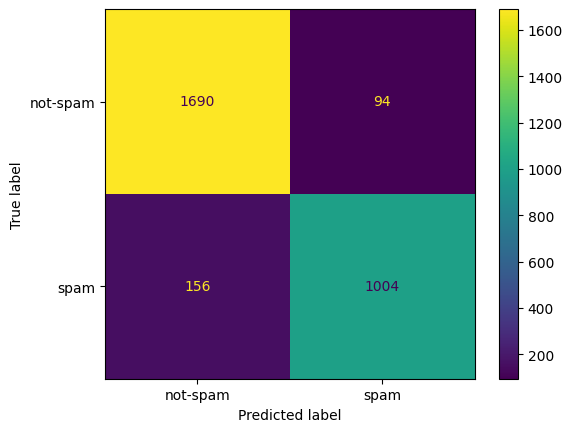

In [ ]:
ypred = cross_val_predict(clf, X, y, cv = T)

# Ploting the confusion matrix
cm = confusion_matrix(y, ypred)

disp = ConfusionMatrixDisplay(confusion_matrix= cm, display_labels= ['not-spam','spam'])
disp.plot()

# Precision
print('Precision score: ', precision_score(y, ypred, average='weighted') * 100)

# Recall
print('Recall score: ', f1_score(y, ypred, average='weighted') * 100)

# F1 score
print('F1 score: ', f1_score(y, ypred, average='weighted') * 100)